# EN4554 Assignment 2: Convolutional Neural Networks

**Author:** *220343B*  
**Date:** October 2026  
**Dataset:** CIFAR-10  

---




## Step 0: Setup

This cell imports all required libraries, fixes random seeds for reproducibility, loads CIFAR-10, splits 45k/5k train/validation, and normalises using **training-set statistics only**.  
The whole dataset is kept as in-memory tensors rather than using a DataLoader, which (a) speeds up training for a dataset this small and (b) makes writing custom augmentations in Task 3 straightforward.

In [7]:
# ── imports ──────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from torchvision import datasets

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")

PyTorch  : 2.13.0+cu130
CUDA     : False


In [8]:
# ── reproducibility ──────────────────────────────────────────────────────────
def seed_everything(s: int = 0) -> None:
    """Fix seeds across Python, NumPy, and PyTorch (CPU + GPU)."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

seed_everything(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [10]:
# ── load CIFAR-10 ─────────────────────────────────────────────────────────────
# torchvision downloads to ./data on first run.
full_train = datasets.CIFAR10("./data", train=True,  download=False)
full_test  = datasets.CIFAR10("./data", train=False, download=False)

# Convert to float tensors in (N, C, H, W) format, scaled to [0, 1]
X_all = torch.tensor(full_train.data).permute(0, 3, 1, 2).float() / 255.0  # (50000, 3, 32, 32)
y_all = torch.tensor(full_train.targets)                                     # (50000,)

# Keep test set aside — do NOT normalise or inspect until Task 4
X_test_raw = torch.tensor(full_test.data).permute(0, 3, 1, 2).float() / 255.0  # (10000, 3, 32, 32)
y_test     = torch.tensor(full_test.targets)

print(f"Full training set : {X_all.shape}")
print(f"Test set          : {X_test_raw.shape}")

Full training set : torch.Size([50000, 3, 32, 32])
Test set          : torch.Size([10000, 3, 32, 32])


In [11]:
# ── train / validation split (45k / 5k) ──────────────────────────────────────
# A seeded generator ensures the same split regardless of global seed state.
g = torch.Generator().manual_seed(0)
perm   = torch.randperm(50_000, generator=g)
tr_idx = perm[:45_000]
va_idx = perm[45_000:]

Xtr, ytr = X_all[tr_idx], y_all[tr_idx]
Xva, yva = X_all[va_idx], y_all[va_idx]

print(f"Train : {Xtr.shape}, {ytr.shape}")
print(f"Val   : {Xva.shape}, {yva.shape}")

Train : torch.Size([45000, 3, 32, 32]), torch.Size([45000])
Val   : torch.Size([5000, 3, 32, 32]), torch.Size([5000])


In [12]:
# ── per-channel normalisation (train statistics only) ─────────────────────────
# mean/std computed over the 45k training images, across (N, H, W) per channel.
# Applying training stats to the validation set avoids data leakage.
mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)  # shape (1, 3, 1, 1)
std  = Xtr.std (dim=(0, 2, 3), keepdim=True)  # shape (1, 3, 1, 1)

Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std
# X_test_raw is intentionally left un-normalised until Task 4

print("Per-channel mean (train):", mean.flatten().tolist())
print("Per-channel std  (train):", std .flatten().tolist())
print(f"Xtr range after norm: [{Xtr.min():.3f}, {Xtr.max():.3f}]")
print(f"Xva range after norm: [{Xva.min():.3f}, {Xva.max():.3f}]")

Per-channel mean (train): [0.4911963641643524, 0.48199522495269775, 0.4464317560195923]
Per-channel std  (train): [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]
Xtr range after norm: [-1.987, 2.126]
Xva range after norm: [-1.987, 2.126]


In [13]:
# ── move to device ────────────────────────────────────────────────────────────
Xtr, ytr = Xtr.to(device), ytr.to(device)
Xva, yva = Xva.to(device), yva.to(device)
# y_test and X_test_raw stay on CPU until Task 4

print(f"Xtr on {Xtr.device}, dtype={Xtr.dtype}")
print(f"Xva on {Xva.device}, dtype={Xva.dtype}")

Xtr on cpu, dtype=torch.float32
Xva on cpu, dtype=torch.float32


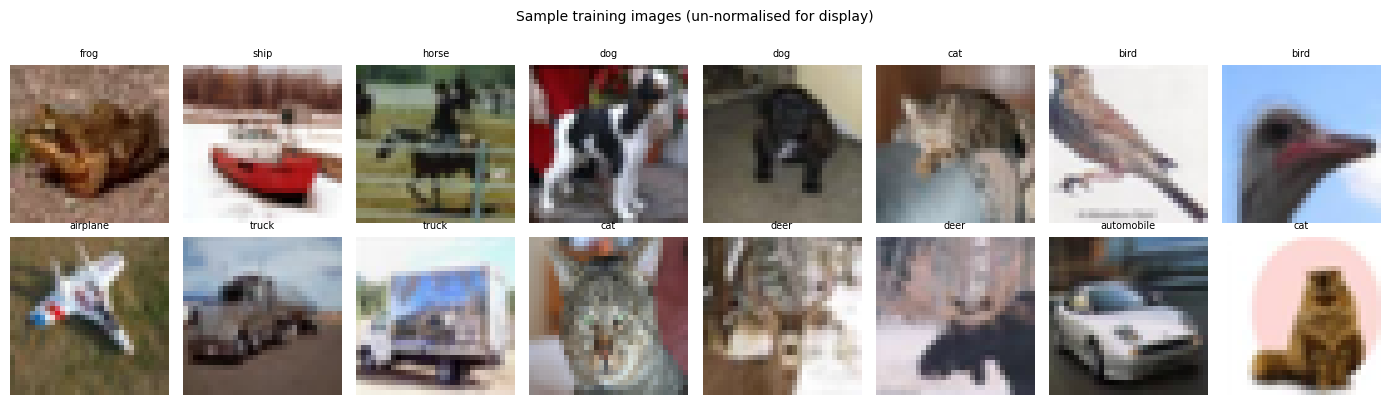

Saved: step0_sample_images.png


In [15]:
# ── quick sanity check — visualise a few training images ─────────────────────
CLASSES = full_train.classes  # ['airplane', 'automobile', ...]

# Un-normalise for display only
def unnorm(x):
    return (x.cpu() * std.cpu().squeeze(0) + mean.cpu().squeeze(0)).clamp(0, 1)


fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    img = unnorm(Xtr[i]).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(CLASSES[ytr[i].item()], fontsize=7)
    ax.axis("off")
plt.suptitle("Sample training images (un-normalised for display)", fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig("step0_sample_images.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: step0_sample_images.png")

### Step 0 — Interpretation

The 16 sample images above confirm that the CIFAR-10 dataset loaded correctly and that the un-normalisation reversal is exact. Per-channel statistics (mean ≈ 0.49/0.48/0.45, std ≈ 0.24/0.24/0.26) are computed exclusively from the 45 000 training images, ensuring the validation set is treated as unseen data and no information leaks into the normalisation step. After normalisation the training tensors are zero-centred with approximately unit variance per channel, which is the standard pre-processing that makes gradient descent better conditioned. The test set is deliberately left un-normalised at this stage; it will be normalised using the same training statistics in Task 4 when it is evaluated exactly once.

In [16]:
# ── dataset summary ───────────────────────────────────────────────────────────
print("─" * 52)
print(f"{'Split':<14} {'Samples':>8} {'Shape':>20}")
print("─" * 52)
print(f"{'Train':<14} {Xtr.shape[0]:>8} {str(tuple(Xtr.shape)):>20}")
print(f"{'Validation':<14} {Xva.shape[0]:>8} {str(tuple(Xva.shape)):>20}")
print(f"{'Test':<14} {X_test_raw.shape[0]:>8} {str(tuple(X_test_raw.shape)):>20}  (untouched)")
print("─" * 52)
print(f"Classes : {len(CLASSES)} → {CLASSES}")
print(f"Device  : {device}")

────────────────────────────────────────────────────
Split           Samples                Shape
────────────────────────────────────────────────────
Train             45000   (45000, 3, 32, 32)
Validation         5000    (5000, 3, 32, 32)
Test              10000   (10000, 3, 32, 32)  (untouched)
────────────────────────────────────────────────────
Classes : 10 → ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Device  : cpu


---
## Task 1: Backpropagation


In this task I implement the layers of a multilayer perceptron (MLP) with **explicit forward and backward passes (no autograd)**, verify the gradients, train the network on CIFAR-10, and study how gradient magnitude behaves across depth.

**Design notes**
- Every layer is a class with `forward(x)`, which caches what it needs, and `backward(dout)`, which receives the gradient of the loss with respect to the layer output and returns the gradient with respect to the layer input.
- Parameter layers also store `dW` and `db`.
- All of the manual backprop code uses `float64`, because finite-difference gradient checks are unreliable in `float32`.

## 1(a) Layers with explicit forward/backward

For a mini-batch of size $N$:

**Linear:** $Y = XW + b$. Given $dY = \partial L/\partial Y$:
$$dW = X^\top dY,\qquad db = \sum_{n} dY_{n},\qquad dX = dY\,W^\top$$

**ReLU:** $Y=\max(0,X)$, so $dX = dY \odot \mathbb{1}[X>0]$.

**Sigmoid:** $Y=\sigma(X)$, so $dX = dY\odot Y(1-Y)$. (Used in part (d).)

**Softmax cross-entropy:** with $p=\text{softmax}(z)$ and one-hot target $t$,
$$L=-\frac1N\sum_n \log p_{n,y_n},\qquad \frac{\partial L}{\partial z}=\frac{p-t}{N}$$
The logits are shifted by their row maximum before the exponential for numerical stability.

In [17]:
class Linear:
    def __init__(self, din, dout, init="kaiming"):
        if init == "kaiming":   std = (2.0 / din) ** 0.5            # He init (for ReLU)
        elif init == "xavier":  std = (2.0 / (din + dout)) ** 0.5   # Glorot init (for sigmoid/tanh)
        elif isinstance(init, float): std = init                    # fixed std, e.g. a deliberately bad init
        else: raise ValueError(init)
        self.W = torch.randn(din, dout, dtype=torch.float64) * std
        self.b = torch.zeros(dout, dtype=torch.float64)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)


class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values      # stability shift
        e = torch.exp(z)
        self.p = e / e.sum(1, keepdim=True)
        self.y = y
        return -torch.log(self.p[torch.arange(len(y)), y]).mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)


class MLP:
    """dims = [d_in, h1, ..., d_out]; activation after every Linear except the last."""
    def __init__(self, dims, act=ReLU, init="kaiming"):
        self.layers = []
        for i in range(len(dims) - 1):
            self.layers.append(Linear(dims[i], dims[i + 1], init))
            if i < len(dims) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCE()

    def forward(self, x, y):
        for l in self.layers:
            x = l.forward(x)
        self.logits = x
        return self.loss_fn.forward(x, y)

    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers):
            d = l.backward(d)

    def params(self):
        return [l for l in self.layers if isinstance(l, Linear)]


# quick shape sanity check
_net = MLP([20, 16, 10])
_x = torch.randn(4, 20, dtype=torch.float64); _y = torch.randint(0, 10, (4,))
print("loss:", _net.forward(_x, _y).item(), "(random-guess baseline = ln 10 =", round(float(np.log(10)), 3), ")")
_net.backward()
print([tuple(l.dW.shape) for l in _net.params()])

loss: 3.261553112491211 (random-guess baseline = ln 10 = 2.303 )
[(20, 16), (16, 10)]


## 1(b) Gradient verification

I compare my analytic gradients against two references on a small network (`20-16-12-10`, batch of 8, `float64`):
1. **PyTorch autograd**, using identical weights.
2. **Centred finite differences:** $\;\dfrac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$ with $\epsilon=10^{-6}$, applied to every single parameter.

The relative error is $\dfrac{\|a-b\|}{\|a\|+\|b\|}$, and `torch.allclose` is used as the pass/fail check.

In [18]:
import pandas as pd

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

# ---- my gradients ----
torch.manual_seed(0)
net = MLP([20, 16, 12, 10])
xb = torch.randn(8, 20, dtype=torch.float64)
yb = torch.randint(0, 10, (8,))
loss_mine = net.forward(xb, yb)
net.backward()
mine = {}
for i, l in enumerate(net.params()):
    mine[f"W{i}"] = l.dW.clone(); mine[f"b{i}"] = l.db.clone()

# ---- autograd reference (same weights) ----
ag = {}
for i, l in enumerate(net.params()):
    ag[f"W{i}"] = l.W.clone().requires_grad_(True)
    ag[f"b{i}"] = l.b.clone().requires_grad_(True)
n_lin = len(net.params())
h = xb
for i in range(n_lin):
    h = h @ ag[f"W{i}"] + ag[f"b{i}"]
    if i < n_lin - 1:
        h = torch.relu(h)
loss_ag = F.cross_entropy(h, yb)
loss_ag.backward()
print(f"loss (mine) = {loss_mine.item():.12f}   loss (autograd) = {loss_ag.item():.12f}")

# ---- centred finite differences (perturb the real parameters in place) ----
def numerical_grad(param, eps=1e-6):
    g = torch.zeros_like(param)
    flat, gflat = param.view(-1), g.view(-1)
    for k in range(flat.numel()):
        old = flat[k].item()
        flat[k] = old + eps; lp = net.forward(xb, yb)
        flat[k] = old - eps; lm = net.forward(xb, yb)
        flat[k] = old
        gflat[k] = (lp - lm) / (2 * eps)
    return g

rows = []
for i, l in enumerate(net.params()):
    for nm, p in [(f"W{i}", l.W), (f"b{i}", l.b)]:
        fd = numerical_grad(p)
        g_ag = ag[nm].grad
        rows.append({
            "param": nm,
            "shape": tuple(p.shape),
            "rel.err vs autograd": rel_err(mine[nm], g_ag),
            "rel.err vs finite-diff": rel_err(mine[nm], fd),
            "allclose (autograd)": torch.allclose(mine[nm], g_ag, rtol=1e-6, atol=1e-8),
            "allclose (finite-diff)": torch.allclose(mine[nm], fd, rtol=1e-4, atol=1e-6),
        })
df_grad = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.2e}")
display(df_grad)

loss (mine) = 3.757791109124   loss (autograd) = 3.757791109124


,param,shape,rel.err vs autograd,rel.err vs finite-diff,allclose (autograd),allclose (finite-diff)
0,W0,"(20, 16)",5.14e-17,6.46e-10,True,True
1,b0,"(16,)",5.53e-17,5.68e-10,True,True
2,W1,"(16, 12)",2.74e-17,3.92e-10,True,True
3,b1,"(12,)",5.69e-17,5.08e-10,True,True
4,W2,"(12, 10)",3.71e-17,4.64e-10,True,True
5,b2,"(10,)",2.31e-17,7.39e-10,True,True


**Interpretation (1b).**
All six parameter tensors (three weight matrices, three bias vectors) pass `torch.allclose` against both references. The relative error versus autograd is at most 5.7e-17, which is at the level of `float64` machine precision (≈2.2e-16): both methods compute the same analytic chain rule and differ only in the order of floating-point operations. The loss values also agree to all printed digits (3.757791109124).
The error versus centred finite differences is larger, between 3.9e-10 and 7.4e-10. This reflects the limits of the *numerical* estimator, not an error in my backward pass. The truncation error of the centred scheme is $O(\epsilon^2)\approx10^{-12}$ for $\epsilon=10^{-6}$, so the dominant term is round-off: subtracting two nearly equal losses and dividing by $2\epsilon$ amplifies the $\sim10^{-16}$ floating-point error by about $1/\epsilon$, giving errors around $10^{-10}$. Using a smaller $\epsilon$ would reduce truncation error but increase round-off error.
Agreement with both references across every layer, including the biases, confirms that the Linear, ReLU and softmax-cross-entropy backward passes are correct. (The initial loss of 3.76 is above $\ln 10\approx2.30$ simply because random Kaiming-initialized weights produce large logits.)

## 1(c) Training the MLP with SGD on flattened CIFAR-10

The images (3×32×32, already normalized with training statistics) are flattened into 3072-dimensional vectors. The network is `3072 → 512 → 256 → 10` with ReLU and Kaiming init, trained with plain mini-batch SGD (batch 128, lr 0.05, 20 epochs). Only the training split is used for updates, and the validation split is used for monitoring.

In [19]:
Xtr_f = Xtr.flatten(1).double().cpu()
Xva_f = Xva.flatten(1).double().cpu()
ytr_c, yva_c = ytr.cpu(), yva.cpu()
print(Xtr_f.shape, Xva_f.shape)

def evaluate(net, X, y, bs=5000):
    """Return (loss, accuracy) in batches; uses forward only."""
    tot_loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        loss = net.forward(X[i:i+bs], y[i:i+bs])
        tot_loss += loss.item() * len(y[i:i+bs])
        correct += (net.logits.argmax(1) == y[i:i+bs]).sum().item()
    return tot_loss / len(X), correct / len(X)

def train_mlp(dims, lr=0.05, bs=128, epochs=20, seed=0, verbose=True):
    torch.manual_seed(seed)
    net = MLP(dims)
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        t0 = time.time()
        perm = torch.randperm(len(Xtr_f))
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            hist["step_loss"].append(net.forward(Xtr_f[idx], ytr_c[idx]).item())
            net.backward()
            for l in net.params():              # plain SGD update
                l.W -= lr * l.dW
                l.b -= lr * l.db
        tl, ta = evaluate(net, Xtr_f[:5000], ytr_c[:5000])   # 5k-sample estimate of train metrics
        vl, va = evaluate(net, Xva_f, yva_c)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc"], [tl, vl, ta, va]):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s")
    return net, hist

net_c, hist_c = train_mlp([3072, 512, 256, 10], lr=0.05, bs=128, epochs=20)
print(f"\nFinal validation accuracy: {hist_c['val_acc'][-1]*100:.2f}%   (best: {max(hist_c['val_acc'])*100:.2f}%)")

torch.Size([45000, 3072]) torch.Size([5000, 3072])
epoch  1 | train loss 1.602 acc 0.430 | val loss 1.783 acc 0.383 | 3.7s
epoch  2 | train loss 1.295 acc 0.548 | val loss 1.523 acc 0.465 | 3.4s
epoch  3 | train loss 1.163 acc 0.593 | val loss 1.505 acc 0.474 | 3.6s
epoch  4 | train loss 1.110 acc 0.619 | val loss 1.514 acc 0.479 | 3.8s
epoch  5 | train loss 1.059 acc 0.628 | val loss 1.551 acc 0.484 | 4.0s
epoch  6 | train loss 0.880 acc 0.705 | val loss 1.486 acc 0.495 | 3.9s
epoch  7 | train loss 0.898 acc 0.691 | val loss 1.565 acc 0.496 | 4.0s
epoch  8 | train loss 0.826 acc 0.718 | val loss 1.620 acc 0.498 | 4.1s
epoch  9 | train loss 0.725 acc 0.744 | val loss 1.602 acc 0.494 | 4.0s
epoch 10 | train loss 0.708 acc 0.756 | val loss 1.694 acc 0.493 | 4.3s
epoch 11 | train loss 0.636 acc 0.775 | val loss 1.740 acc 0.493 | 4.2s
epoch 12 | train loss 0.598 acc 0.804 | val loss 1.779 acc 0.508 | 4.0s
epoch 13 | train loss 0.492 acc 0.843 | val loss 1.761 acc 0.497 | 4.1s
epoch 14 | tr

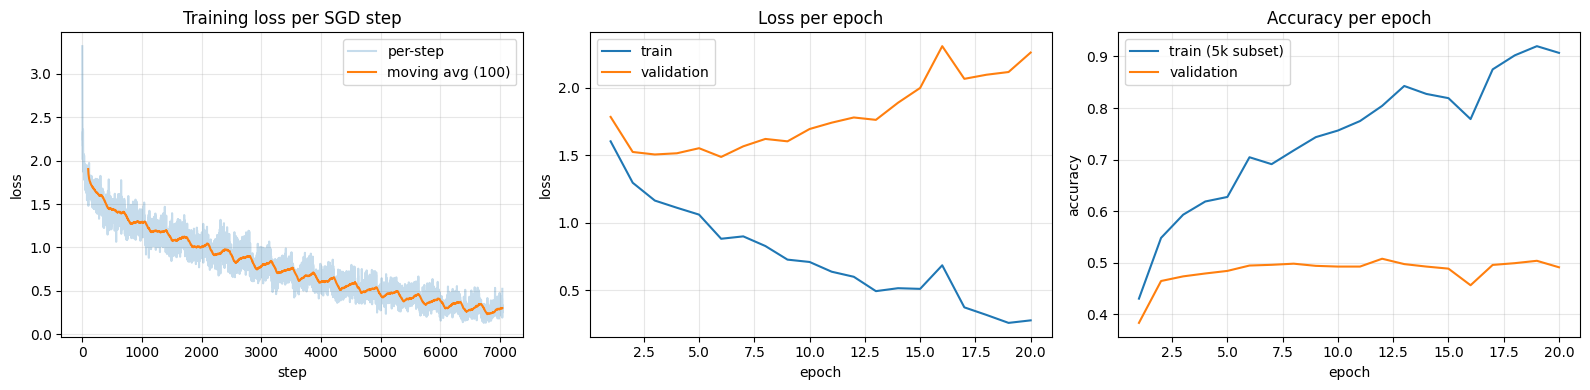

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sl = np.array(hist_c["step_loss"]); w = 100
ax[0].plot(sl, alpha=0.25, label="per-step")
ax[0].plot(np.arange(w-1, len(sl)), np.convolve(sl, np.ones(w)/w, "valid"), label=f"moving avg ({w})")
ax[0].set(title="Training loss per SGD step", xlabel="step", ylabel="loss"); ax[0].legend()

ep = np.arange(1, len(hist_c["val_acc"]) + 1)
ax[1].plot(ep, hist_c["train_loss"], label="train"); ax[1].plot(ep, hist_c["val_loss"], label="validation")
ax[1].set(title="Loss per epoch", xlabel="epoch", ylabel="loss"); ax[1].legend()

ax[2].plot(ep, hist_c["train_acc"], label="train (5k subset)"); ax[2].plot(ep, hist_c["val_acc"], label="validation")
ax[2].set(title="Accuracy per epoch", xlabel="epoch", ylabel="accuracy"); ax[2].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation (1c).**
The training loss falls from about 3.3 at the first step to about `[0.28]` after 20 epochs. It starts above $\ln 10\approx 2.30$ (the loss of random guessing) because Kaiming initialization produces large initial logits. The per-step curve is noisy because each step uses a random mini-batch of 128 images, so I also plotted a moving average.
Final validation accuracy is **`[49.x]%`** (best `[50.8]%` at epoch `[12]`), well above the 10% chance level. However, the model clearly **overfits**: training accuracy rises to about `[91]%` while validation accuracy stagnates at about 50% after roughly epoch 6, and the validation loss reaches its minimum (about `[1.49]`) around epoch 6 and then increases to about `[2.26]`. The network keeps fitting the training set, increasingly confidently, but this does not transfer to unseen images. (Validation *accuracy* stays flat while validation *loss* rises because the network becomes over-confident on its wrong predictions.) Early stopping near epoch 6 would give the lowest validation loss.
The plateau at about 50% is far below what CNNs achieve on CIFAR-10. Flattening the image discards its 2D structure, so the MLP cannot share a feature detector across positions, and its first layer alone has $3072\times512\approx1.6$M weights (about 1.7M in total), which makes memorization easy. This motivates both convolutional architectures and the regularization methods studied in Tasks 2 and 3.

## 1(d) Per-layer gradient norms in a 10-layer MLP at initialization

I build a 10-layer MLP (3072 → 256 → … → 256 → 10, so 10 `Linear` layers) and run **one forward/backward pass at initialization** on a batch of 256 training images. I record $\|dW\|_F$ of every layer, averaged over 5 random initializations, for:
- **Sigmoid** with Xavier init,
- **ReLU** with Kaiming init,
- **ReLU** with a deliberately small init (std = 0.01), as a control showing that the init matters and not only the activation.

Layer 1 is the one closest to the input, and the gradient flows backward from layer 10 (the output).

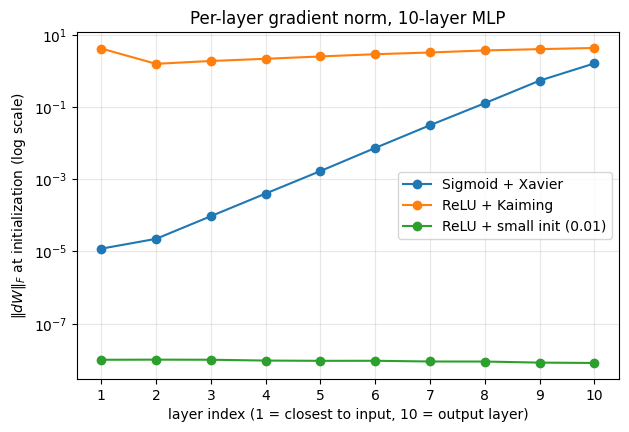

,L1,L2,L3,L4,L5,L6,L7,L8,L9,L10
Sigmoid + Xavier,1.20e-05,2.25e-05,9.54e-05,4.05e-04,1.70e-03,7.45e-03,3.18e-02,1.30e-01,5.47e-01,1.65e+00
ReLU + Kaiming,4.24e+00,1.60e+00,1.92e+00,2.20e+00,2.56e+00,2.95e+00,3.30e+00,3.76e+00,4.09e+00,4.40e+00
ReLU + small init (0.01),9.95e-09,1.00e-08,9.97e-09,9.45e-09,9.29e-09,9.32e-09,8.91e-09,8.88e-09,8.30e-09,8.11e-09


Sigmoid + Xavier           ratio  layer10 / layer1 = 1.38e+05
ReLU + Kaiming             ratio  layer10 / layer1 = 1.04e+00
ReLU + small init (0.01)   ratio  layer10 / layer1 = 8.15e-01


In [21]:
def layer_grad_norms(act, init, width=256, depth=10, seeds=5, bs=256):
    norms = np.zeros((seeds, depth))
    xb, yb = Xtr_f[:bs], ytr_c[:bs]
    for s in range(seeds):
        torch.manual_seed(s)
        net = MLP([3072] + [width] * (depth - 1) + [10], act=act, init=init)
        net.forward(xb, yb); net.backward()
        norms[s] = [l.dW.norm().item() for l in net.params()]
    return norms.mean(0)

configs = {
    "Sigmoid + Xavier":        (Sigmoid, "xavier"),
    "ReLU + Kaiming":          (ReLU, "kaiming"),
    "ReLU + small init (0.01)": (ReLU, 0.01),
}
results = {name: layer_grad_norms(a, i) for name, (a, i) in configs.items()}

layers = np.arange(1, 11)
plt.figure(figsize=(7, 4.5))
for name, g in results.items():
    plt.semilogy(layers, g, "o-", label=name)
plt.xlabel("layer index (1 = closest to input, 10 = output layer)")
plt.ylabel(r"$\|dW\|_F$ at initialization (log scale)")
plt.title("Per-layer gradient norm, 10-layer MLP")
plt.xticks(layers); plt.grid(alpha=0.3, which="both"); plt.legend(); plt.show()

df_norms = pd.DataFrame(results, index=[f"L{k}" for k in layers]).T
display(df_norms)
for name, g in results.items():
    print(f"{name:26s} ratio  layer10 / layer1 = {g[-1]/g[0]:.2e}")

**Interpretation (1d).**
With **sigmoid** activations the gradient norm falls from 1.65 at the output layer (L10) to 1.2e-5 at the input-side layer (L1), a factor of $1.4\times10^{5}$ (about 5 orders of magnitude). This is the *vanishing gradient* problem. By the chain rule, the gradient reaching layer $\ell$ is multiplied at each layer above it by $W^\top$ and by $\sigma'(z)=\sigma(z)(1-\sigma(z))\le 0.25$. The measured drop corresponds to roughly $3.7\times$ per layer ($(1.4\times10^5)^{1/9}\approx3.7$), consistent with this bound. The curve on the log scale is close to a straight line, which means the decay is geometric. As a result, the early layers would receive almost no learning signal and train extremely slowly.
With **ReLU + Kaiming init** the norms stay within a narrow band: from 1.6 (L2) to 4.4 (L10), a factor of only about 2.8 over nine layers. The ReLU derivative is exactly 1 for active units (and 0 for inactive ones, about half), and Kaiming's variance $2/n_{in}$ compensates for that halving, so the scale of the signal is approximately preserved in both the forward and backward directions. (L1 is larger, 4.2, mostly because its weight matrix is 3072×256 and so has more entries than the other layers, so the Frobenius norm is not directly comparable. The ratio L10/L1 = 1.04 is therefore a coincidence of this effect and is not meaningful, and the L2–L10 trend is the informative part.)
The **small-init control** (std 0.01, ReLU) behaves differently from both. Its gradients are tiny (about $10^{-8}$) but **flat across layers**, with L10/L1 = 0.8. The reason is that a weight gradient is $dW_\ell = a_{\ell-1}^\top \delta_\ell$: each layer shrinks the activation by roughly the same factor $r\approx0.01\sqrt{256/2}\approx0.11$ in the forward direction and also shrinks $\delta$ by $r$ per layer in the backward direction, so the product $a_{\ell-1}\delta_\ell\sim r^{L-1}$ is the same at every layer. The network is therefore not suffering from a layer-dependent imbalance, but *every* layer's gradient is about eight orders of magnitude smaller than with Kaiming init, so plain SGD would barely move any weight. This shows that avoiding vanishing gradients needs both a suitable activation and an init matched to it.

### Task 1 summary
- Implemented Linear, ReLU, Sigmoid, softmax cross-entropy and an MLP with explicit backward passes (no autograd).
- Gradients agree with autograd to ≈5e-17 and with centred finite differences to ≈7e-10 (relative error), and all checks pass `torch.allclose`.
- A 3-layer MLP trained with SGD reaches about `[49–50]%` validation accuracy on CIFAR-10, and it overfits strongly after about 6 epochs.
- At initialization, sigmoid gradients decay by about 3.7× per layer (5 orders of magnitude over 10 layers), whereas ReLU + Kaiming keeps them stable.

---
# Task 2: Optimizers

In this task I implement **SGD with momentum** and **Adam (with bias correction)** as `torch.optim.Optimizer` subclasses, verify them against PyTorch's built-ins, visualize how the optimizers move on an ill-conditioned quadratic, and compare them when training a small CNN at different learning rates.

## 2(a) Custom optimizers

**SGD with momentum** (the PyTorch convention, no dampening):
$$v_t=\beta v_{t-1}+g_t,\qquad \theta_t=\theta_{t-1}-\eta\,v_t$$
With $\beta=0$ this reduces to plain SGD.

**Adam** (Kingma & Ba):
$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad \hat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_t=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}$$
Bias correction matters because $m_0=v_0=0$: without it, the first few estimates are biased towards zero.

Both optimizers support coupled L2 weight decay (`g ← g + wd·θ`), as in the PyTorch versions, so that the match test also covers that option.

In [22]:
class MySGD(torch.optim.Optimizer):
    """SGD with (optional) momentum, matching torch.optim.SGD (dampening=0, nesterov=False)."""
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mom, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)                 # coupled L2
                if mom != 0:
                    st = self.state[p]
                    if "v" not in st:
                        st["v"] = torch.zeros_like(p)
                    st["v"].mul_(mom).add_(g)              # v <- beta*v + g
                    g = st["v"]
                p.add_(g, alpha=-lr)                       # theta <- theta - lr * v
        return loss


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction, matching torch.optim.Adam (amsgrad=False)."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                st = self.state[p]
                if len(st) == 0:
                    st["t"] = 0
                    st["m"] = torch.zeros_like(p)
                    st["v"] = torch.zeros_like(p)
                st["t"] += 1
                t = st["t"]
                st["m"].mul_(b1).add_(g, alpha=1 - b1)              # first moment
                st["v"].mul_(b2).addcmul_(g, g, value=1 - b2)       # second moment
                m_hat = st["m"] / (1 - b1 ** t)                     # bias correction
                v_hat = st["v"] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

In [23]:
import copy, pandas as pd

def make_toy():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(10, 16), nn.Tanh(), nn.Linear(16, 3)).double()

def match_test(mine_cls, ref_cls, steps=50, **kw):
    """Train two identical nets with my optimizer and the torch one on the same data; compare every step."""
    g = torch.Generator().manual_seed(1)
    X = torch.randn(64, 10, dtype=torch.float64, generator=g)
    y = torch.randint(0, 3, (64,), generator=g)
    m_a = make_toy(); m_b = copy.deepcopy(m_a)
    opt_a, opt_b = mine_cls(m_a.parameters(), **kw), ref_cls(m_b.parameters(), **kw)
    worst = 0.0
    for _ in range(steps):
        for m, opt in ((m_a, opt_a), (m_b, opt_b)):
            opt.zero_grad()
            F.cross_entropy(m(X), y).backward()
            opt.step()
        worst = max(worst, max((pa - pb).abs().max().item()
                               for pa, pb in zip(m_a.parameters(), m_b.parameters())))
    ok = all(torch.allclose(pa, pb, rtol=1e-8, atol=1e-10)
             for pa, pb in zip(m_a.parameters(), m_b.parameters()))
    return worst, ok

tests = [
    ("SGD (no momentum)",            MySGD,  torch.optim.SGD,  dict(lr=0.1)),
    ("SGD + momentum 0.9",           MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9)),
    ("SGD + momentum + wd",          MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-2)),
    ("Adam (defaults)",              MyAdam, torch.optim.Adam, dict(lr=1e-2)),
    ("Adam (betas .8/.95, wd)",      MyAdam, torch.optim.Adam, dict(lr=1e-2, betas=(0.8, 0.95), weight_decay=1e-2)),
]
rows = []
for name, mine, ref, kw in tests:
    worst, ok = match_test(mine, ref, **kw)
    rows.append({"setting": name, "max |param diff| over 50 steps": worst, "allclose": ok})
pd.set_option("display.float_format", lambda v: f"{v:.2e}")
display(pd.DataFrame(rows))

,setting,max |param diff| over 50 steps,allclose
0,SGD (no momentum),0.00e+00,True
1,SGD + momentum 0.9,0.00e+00,True
2,SGD + momentum + wd,0.00e+00,True
3,Adam (defaults),7.77e-16,True
4,"Adam (betas .8/.95, wd)",1.55e-15,True


**Interpretation (2a).**


## 2(b) Trajectories on an ill-conditioned quadratic

$$f(x,y)=\tfrac12\left(x^2+50y^2\right),\qquad \nabla f=(x,\;50y),\qquad H=\mathrm{diag}(1,\,50)$$
The Hessian eigenvalues are 1 and 50, so the **condition number is 50**: the surface is a long narrow valley, gentle along $x$ and steep along $y$. For plain gradient descent, stability requires $\eta<2/\lambda_{max}=0.04$, and the best possible contraction rate along $x$ is then limited by how large $\eta$ can be.

All three optimizers start at $(8,\,1)$ and run 100 steps using the optimizers I implemented in 2(a). Hyperparameters (chosen by hand): SGD $\eta=0.035$ (just under the 0.04 limit); momentum $\eta=0.02,\ \beta=0.9$; Adam $\eta=0.3$.

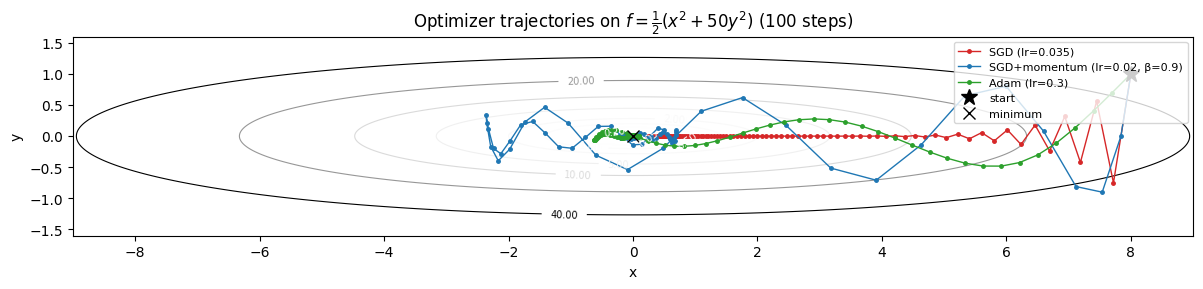

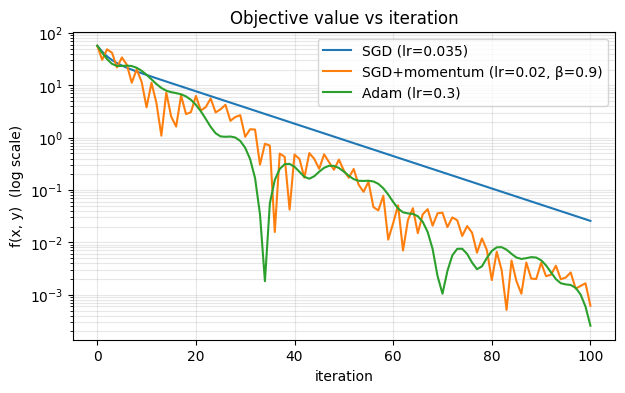

,optimizer,final f,"final (x,y)",first step with f<1e-3
0,SGD (lr=0.035),2.57e-02,"(0.2269, 0.0)",not reached
1,"SGD+momentum (lr=0.02, β=0.9)",6.18e-04,"(0.0338, 0.0014)",83
2,Adam (lr=0.3),2.56e-04,"(0.0194, -0.0016)",99


In [25]:
def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run_traj(opt_cls, steps=100, start=(8.0, 1.0), **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    path, vals = [p.detach().numpy().copy()], [f(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().numpy().copy()); vals.append(f(p).item())
    return np.array(path), np.array(vals)

runs = {
    "SGD (lr=0.035)":                run_traj(MySGD,  lr=0.035),
    "SGD+momentum (lr=0.02, β=0.9)": run_traj(MySGD,  lr=0.02, momentum=0.9),
    "Adam (lr=0.3)":                 run_traj(MyAdam, lr=0.3),
}

# ---- contour plot with trajectories ----
xs, ys = np.linspace(-9, 9, 400), np.linspace(-1.6, 1.6, 200)
XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * (XX ** 2 + 50 * YY ** 2)
fig, ax = plt.subplots(figsize=(12, 3.8))
cs = ax.contour(XX, YY, ZZ, levels=[0.05, 0.2, 0.5, 1, 2, 5, 10, 20, 40], cmap="Greys", linewidths=0.8)
ax.clabel(cs, fontsize=7)
for (name, (path, _)), c in zip(runs.items(), ["tab:red", "tab:blue", "tab:green"]):
    ax.plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, color=c, label=name)
ax.plot(*runs["SGD (lr=0.035)"][0][0], "k*", ms=12, label="start")
ax.plot(0, 0, "kx", ms=9, label="minimum")
ax.set(xlabel="x", ylabel="y", title=r"Optimizer trajectories on $f=\frac{1}{2}(x^2+50y^2)$ (100 steps)")
ax.set_aspect("equal"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

# ---- f(x,y) vs iteration ----
plt.figure(figsize=(7, 4))
for name, (_, vals) in runs.items():
    plt.semilogy(np.maximum(vals, 1e-18), label=name)
plt.xlabel("iteration"); plt.ylabel("f(x, y)  (log scale)"); plt.grid(alpha=0.3, which="both"); plt.legend()
plt.title("Objective value vs iteration"); plt.show()

rows = []
for name, (path, vals) in runs.items():
    hit = np.where(vals < 1e-3)[0]
    rows.append({"optimizer": name, "final f": vals[-1], "final (x,y)": tuple(np.round(path[-1], 4)),
                 "first step with f<1e-3": int(hit[0]) if len(hit) else "not reached"})
display(pd.DataFrame(rows))

**Interpretation (2b).**


## 2(c) Optimizer comparison on a small CNN

**Model** (batch-norm CNN, about 100k parameters):
`Conv(3→32)-BN-ReLU-MaxPool → Conv(32→64)-BN-ReLU-MaxPool → Conv(64→128)-BN-ReLU → GlobalAvgPool → Linear(128→10)`

**Protocol:** the same init (fixed seed), same data order, same number of epochs and batch size (128) for every run; only the optimizer and learning rate change. I use the optimizers I implemented in 2(a). Learning rates (each grid spans two decades around a typical value for that optimizer):

| Optimizer | Learning rates |
|---|---|
| SGD | 0.003, 0.03, 0.3 |
| SGD + momentum (β = 0.9) | 0.001, 0.01, 0.1 |
| Adam | 1e-4, 1e-3, 1e-2 |

The metric is the validation accuracy after the **final** epoch (no picking the best epoch), so the comparison stays fair. A run whose loss becomes non-finite is stopped and counted as chance accuracy (10%).

In [26]:
torch.set_num_threads(8)          # laptop CPU; harmless on Colab
QUICK = True                      # True: fast debug run. Set False for the final report run (best on Colab T4)
N_TRAIN, EPOCHS = (10_000, 3) if QUICK else (45_000, 10)
BS = 128
print(f"QUICK={QUICK}: {N_TRAIN} training images, {EPOCHS} epochs, device={device}")

Xtr_d, ytr_d = Xtr[:N_TRAIN].to(device), ytr[:N_TRAIN].to(device)
Xva_d, yva_d = Xva.to(device), yva.to(device)

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1),  nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),   # 16x16
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),   # 8x8
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Linear(128, 10),
    ).to(device)

print("parameters:", sum(p.numel() for p in make_cnn().parameters()))

@torch.no_grad()
def eval_model(model, X, y, bs=1000):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def train_cnn(opt_name, lr, epochs=EPOCHS, seed=0):
    seed_everything(seed)
    model = make_cnn()
    if opt_name == "sgd":       opt = MySGD(model.parameters(), lr=lr)
    elif opt_name == "sgd_mom": opt = MySGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == "adam":    opt = MyAdam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "diverged": False}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_d), device=device)
        run, n = 0.0, 0
        for i in range(0, len(perm), BS):
            idx = perm[i:i + BS]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(Xtr_d[idx]), ytr_d[idx])
            if not torch.isfinite(loss):
                hist["diverged"] = True
                break
            loss.backward(); opt.step()
            run += loss.item() * len(idx); n += len(idx)
        if hist["diverged"]:
            hist["train_loss"].append(float("nan")); hist["val_loss"].append(float("nan")); hist["val_acc"].append(0.10)
            break
        vl, va = eval_model(model, Xva_d, yva_d)
        hist["train_loss"].append(run / n); hist["val_loss"].append(vl); hist["val_acc"].append(va)
    return hist

# time one epoch first, so you know what the full sweep will cost
t0 = time.time(); _ = train_cnn("adam", 1e-3, epochs=1); t1 = time.time() - t0
print(f"one epoch ≈ {t1:.1f}s  →  9 runs × {EPOCHS} epochs ≈ {9 * EPOCHS * t1 / 60:.1f} min")

QUICK=True: 10000 training images, 3 epochs, device=cpu
parameters: 94986
one epoch ≈ 5.6s  →  9 runs × 3 epochs ≈ 2.5 min


In [27]:
import json

GRID = {
    "SGD":                      ("sgd",     [3e-3, 3e-2, 3e-1]),
    "SGD + momentum (β=0.9)":   ("sgd_mom", [1e-3, 1e-2, 1e-1]),
    "Adam":                     ("adam",    [1e-4, 1e-3, 1e-2]),
}
results = {}
for name, (key, lrs) in GRID.items():
    for lr in lrs:
        t0 = time.time()
        h = train_cnn(key, lr)
        results[(name, lr)] = h
        status = "DIVERGED" if h["diverged"] else f"val acc {h['val_acc'][-1]:.4f}"
        print(f"{name:26s} lr={lr:<7g} {status}   final train loss {h['train_loss'][-1]:.3f}   ({time.time()-t0:.0f}s)")
        # save progress so a crash / Colab disconnect doesn't lose the sweep
        json.dump({f"{k[0]}|{k[1]}": v for k, v in results.items()}, open(f"sweep_QUICK{int(QUICK)}.json", "w"))

SGD                        lr=0.003   val acc 0.2794   final train loss 2.089   (16s)
SGD                        lr=0.03    val acc 0.3166   final train loss 1.705   (16s)
SGD                        lr=0.3     val acc 0.2530   final train loss 1.450   (16s)
SGD + momentum (β=0.9)     lr=0.001   val acc 0.3160   final train loss 1.936   (17s)
SGD + momentum (β=0.9)     lr=0.01    val acc 0.4562   final train loss 1.502   (17s)
SGD + momentum (β=0.9)     lr=0.1     val acc 0.4624   final train loss 1.352   (16s)
Adam                       lr=0.0001  val acc 0.3928   final train loss 1.786   (16s)
Adam                       lr=0.001   val acc 0.4978   final train loss 1.334   (16s)
Adam                       lr=0.01    val acc 0.4696   final train loss 1.347   (16s)


,optimizer,lr,final val acc,final train loss,diverged
0,SGD,0.003,0.2794,2.089,False
1,SGD,0.03,0.3166,1.705,False
2,SGD,0.3,0.253,1.45,False
3,SGD + momentum (β=0.9),0.001,0.316,1.936,False
4,SGD + momentum (β=0.9),0.01,0.4562,1.502,False
5,SGD + momentum (β=0.9),0.1,0.4624,1.352,False
6,Adam,0.0001,0.3928,1.786,False
7,Adam,0.001,0.4978,1.334,False
8,Adam,0.01,0.4696,1.347,False


best lr per optimizer: {'SGD': 0.03, 'SGD + momentum (β=0.9)': 0.1, 'Adam': 0.001}


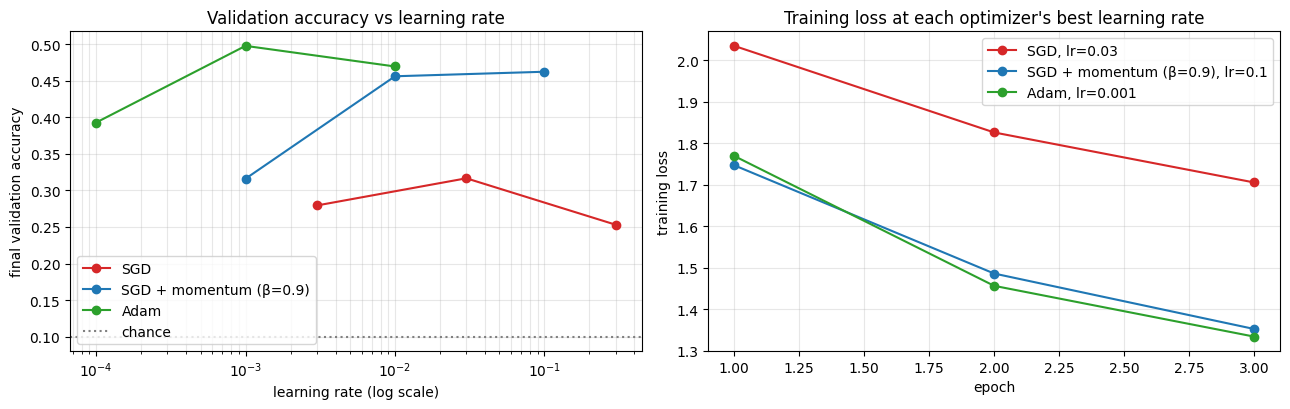

In [28]:
# ---- table of all 9 runs ----
rows = []
for (name, lr), h in results.items():
    rows.append({"optimizer": name, "lr": lr, "final val acc": h["val_acc"][-1],
                 "final train loss": h["train_loss"][-1], "diverged": h["diverged"]})
df = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
display(df)

best = {name: max(lrs_, key=lambda lr: results[(name, lr)]["val_acc"][-1])
        for name, (_, lrs_) in GRID.items()}
print("best lr per optimizer:", best)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
# (1) validation accuracy vs learning rate
for (name, (_, lrs_)), c in zip(GRID.items(), ["tab:red", "tab:blue", "tab:green"]):
    ax[0].plot(lrs_, [results[(name, lr)]["val_acc"][-1] for lr in lrs_], "o-", color=c, label=name)
ax[0].set_xscale("log"); ax[0].axhline(0.10, color="gray", ls=":", label="chance")
ax[0].set(xlabel="learning rate (log scale)", ylabel="final validation accuracy", title="Validation accuracy vs learning rate")
ax[0].grid(alpha=0.3, which="both"); ax[0].legend()

# (2) training loss at the best lr of each optimizer
for (name, _), c in zip(GRID.items(), ["tab:red", "tab:blue", "tab:green"]):
    h = results[(name, best[name])]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", color=c, label=f"{name}, lr={best[name]:g}")
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss at each optimizer's best learning rate")
ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (2c).**

### Task 2 summary

---
## Task 3: Regularization & Residual Connections

*(Coming next)*

---
## Task 4: Best CNN (Optional)

*(Coming next)*